In [2]:
import os, time, traceback, warnings
from itertools import combinations, permutations
import numpy as np, pandas as pd, tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, callbacks, regularizers
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_absolute_error
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

OUT = "deep_trig_run"; os.makedirs(OUT, exist_ok=True)
LOG = open(f"{OUT}/results.txt", "w", encoding="utf-8")
def log(*a):
    s = " ".join(str(v) for v in a)
    print(s, flush=True); LOG.write(s + "\n"); LOG.flush()

# ---------------- data and split (same as the first run) ----------------
SEED = 42
df = pd.read_csv("data.csv")
d = {k: df[k].values.astype("float64") for k in ("x", "y", "z")}
f = df["f"].values.astype("float64")
idx = np.arange(len(df))
i_tmp, i_te = train_test_split(idx, test_size=0.10, random_state=SEED)
i_tr, i_va = train_test_split(i_tmp, test_size=0.15 / 0.90, random_state=SEED)
log(f"train={len(i_tr)} val={len(i_va)} test={len(i_te)}")

# ---------------- feature bank: all permutations of x, y, z x common functions ----------------
def build_features(d):
    names = ["x", "y", "z"]
    Q = {}                                            # quantity name -> values

    # 1) quantities built from combinations / permutations of x, y, z
    for a in names:
        Q[a] = d[a]
    for a, b in combinations(names, 2):               # symmetric pair quantities
        Q[f"{a}{b}"] = d[a] * d[b]
        Q[f"({a}+{b})"] = d[a] + d[b]
        Q[f"({a}-{b})"] = d[a] - d[b]
        Q[f"hyp({a},{b})"] = np.hypot(d[a], d[b])
    for a, b in permutations(names, 2):               # ordered pair quantities
        Q[f"{a}/({b}^2+1)"] = d[a] / (d[b]**2 + 1.0)
        Q[f"{a}*{b}/({b}^2+1)"] = d[a] * d[b] / (d[b]**2 + 1.0)   # includes y*z/(z^2+1)
    for c in names:                                   # triple quantities (no duplicates)
        a, b = [n for n in names if n != c]
        Q[f"{a}{b}/({c}^2+1)"] = d[a] * d[b] / (d[c]**2 + 1.0)
        Q[f"{c}/({a}^2+{b}^2+1)"] = d[c] / (d[a]**2 + d[b]**2 + 1.0)
    Q["xyz"] = d["x"] * d["y"] * d["z"]
    Q["(x+y+z)"] = d["x"] + d["y"] + d["z"]
    Q["hyp(x,y,z)"] = np.sqrt(d["x"]**2 + d["y"]**2 + d["z"]**2)

    # 2) the same common functions applied to every quantity
    F = {}
    for n, q in Q.items():
        S = np.max(np.abs(q)) + 1e-12                 # scale so exp cannot overflow
        F[n] = q                                      # the quantity itself (StandardScaler handles scale)
        F[f"sin({n})"], F[f"cos({n})"] = np.sin(q), np.cos(q)
        F[f"sin({n}/10)"], F[f"cos({n}/10)"] = np.sin(q / 10), np.cos(q / 10)
        F[f"sin({n}/100)"], F[f"cos({n}/100)"] = np.sin(q / 100), np.cos(q / 100)
        F[f"tanh({n})"] = np.tanh(q / S * 3)
        F[f"exp({n}/S)"], F[f"exp(-{n}/S)"] = np.exp(q / S), np.exp(-q / S)
        F[f"log1p|{n}|"] = np.log1p(np.abs(q))
        F[f"slog({n})"] = np.sign(q) * np.log1p(np.abs(q))
        F[f"sqrt|{n}|"] = np.sqrt(np.abs(q))
        F[f"({n})^2"] = q**2
        F[f"{n}/({n}^2+1)"] = q / (q**2 + 1.0)
        F[f"1/({n}^2+1)"] = 1.0 / (q**2 + 1.0)

    # 3) trig cross terms
    for a, b in combinations(names, 2):
        F[f"sin({a})sin({b})"] = np.sin(d[a]) * np.sin(d[b])
        F[f"cos({a})cos({b})"] = np.cos(d[a]) * np.cos(d[b])
        F[f"sin({a})cos({b})"] = np.sin(d[a]) * np.cos(d[b])
        F[f"cos({a})sin({b})"] = np.cos(d[a]) * np.sin(d[b])
    F["sin(x)sin(y)sin(z)"] = np.sin(d["x"]) * np.sin(d["y"]) * np.sin(d["z"])
    F["cos(x)cos(y)cos(z)"] = np.cos(d["x"]) * np.cos(d["y"]) * np.cos(d["z"])
    return F

F_all = build_features(d)
bank_names = list(F_all.keys())
base_names = ["x", "y", "z", "y*z/(z^2+1)"]           # same 4 inputs as the original model
for n in base_names:
    assert n in F_all, f"base feature missing: {n}"
for n in bank_names:
    assert np.all(np.isfinite(F_all[n])), f"non-finite values in feature {n}"
log(f"bank feature count = {len(bank_names)} | base inputs = {len(base_names)}")

def matrix(names, ii):
    return np.column_stack([F_all[n][ii] for n in names]).astype("float64")

f_mean, f_std = f[i_tr].mean(), f[i_tr].std()          # target scaling, train only
t_tr, t_va = (f[i_tr] - f_mean) / f_std, (f[i_va] - f_mean) / f_std

# ---------------- models ----------------
def make_net(n_in, widths):
    reg = regularizers.l2(1e-6)
    m = keras.Sequential([layers.Input(shape=(n_in,))])
    for w_ in widths:
        m.add(layers.Dense(w_, activation="tanh", kernel_regularizer=reg))
    m.add(layers.Dense(1))
    return m

def real_pred(net, X):
    return net.predict(X, batch_size=1024, verbose=0).ravel() * f_std + f_mean

def rmse(a, b):
    return float(np.sqrt(np.mean((a - b)**2)))

def run(tag, names, widths, seed):
    tf.keras.utils.set_random_seed(seed)
    Xtr, Xva, Xte = (matrix(names, ii) for ii in (i_tr, i_va, i_te))
    sc = StandardScaler().fit(Xtr)
    Xtr, Xva, Xte = sc.transform(Xtr), sc.transform(Xva), sc.transform(Xte)
    net = make_net(Xtr.shape[1], widths)
    net.compile(optimizer=keras.optimizers.Adam(1e-3), loss="mse")
    t0 = time.time()
    h = net.fit(Xtr, t_tr, validation_data=(Xva, t_va), epochs=300, batch_size=256, verbose=0,
                callbacks=[callbacks.ReduceLROnPlateau(factor=0.5, patience=10, min_lr=1e-6),
                           callbacks.EarlyStopping(patience=30, min_delta=1e-4, restore_best_weights=True)])
    pv = real_pred(net, Xva)
    ptr = real_pred(net, Xtr)
    res = dict(net=net, Xva=Xva, Xte=Xte, val_rmse=rmse(pv, f[i_va]), train_rmse=rmse(ptr, f[i_tr]),
               val_r2=float(r2_score(f[i_va], pv)), epochs=len(h.history["loss"]))
    log(f"[{tag} seed={seed}] epochs={res['epochs']} time={time.time()-t0:.0f}s | "
        f"train RMSE={res['train_rmse']:.4f} | val RMSE={res['val_rmse']:.4f} R2={res['val_r2']:.5f}")
    return res

# ---------------- run the three arms ----------------
W4 = [256, 256, 128, 64]
W5 = [256, 256, 128, 64, 32]
plan = [("base4", base_names, W4), ("deep4in", base_names, W5), ("deepbank", bank_names, W5)]
results = {}
for tag, names, widths in plan:
    for seed in (1, 2):
        try:
            results[(tag, seed)] = run(tag, names, widths, seed)
        except Exception:
            log(f"[{tag} seed={seed}] FAILED:\n" + traceback.format_exc())

# ---------------- choose on VALIDATION, look at test once ----------------
log("\n=== VALIDATION SUMMARY (RMSE in real f units) ===")
summ = {}
for tag, _, _ in plan:
    rs = [v for k, v in results.items() if k[0] == tag]
    if rs:
        summ[tag] = np.mean([v["val_rmse"] for v in rs])
        log(f"{tag:9s} mean val RMSE={summ[tag]:.4f}  (per seed: "
            + ", ".join(f"{v['val_rmse']:.4f}" for v in rs) + ")")

if "base4" in summ:
    b = [v["val_rmse"] for k, v in results.items() if k[0] == "base4"]
    noise = abs(b[0] - b[1]) if len(b) == 2 else 0.0
    log(f"\nbase4 seed-to-seed gap = {noise:.4f}")
    for tag in summ:
        if tag != "base4":
            gain = summ["base4"] - summ[tag]
            verdict = ("BETTER than base4" if gain > 3 * noise and gain > 0.01
                       else "WORSE than base4" if gain < -3 * noise
                       else "same as base4 (within noise)")
            log(f"{tag:9s} gain vs base4 = {gain:+.4f}  -> {verdict}")
    best = min(summ, key=summ.get)
    log("\n=== TEST (looked at once, after choosing) ===")
    for tag in dict.fromkeys([best, "base4"]):
        key = min((k for k in results if k[0] == tag), key=lambda k: results[k]["val_rmse"])
        r_ = results[key]
        pt = real_pred(r_["net"], r_["Xte"])
        log(f"{tag:9s} test RMSE={rmse(pt, f[i_te]):.4f} MAE={mean_absolute_error(f[i_te], pt):.4f} "
            f"R2={r2_score(f[i_te], pt):.5f}")

# ---------------- permutation importance for the bank model (validation) ----------------
N_REPEATS = 2                                          # raise for stabler estimates (slower)
try:
    key = min((k for k in results if k[0] == "deepbank"), key=lambda k: results[k]["val_rmse"])
    r_ = results[key]; net, Xva = r_["net"], r_["Xva"]
    base_r = rmse(real_pred(net, Xva), f[i_va])
    rng = np.random.default_rng(0)
    imp = []
    for j in range(len(bank_names)):
        inc = []
        for _ in range(N_REPEATS):
            Xp = Xva.copy(); Xp[:, j] = rng.permutation(Xp[:, j])
            inc.append(rmse(real_pred(net, Xp), f[i_va]) - base_r)
        imp.append(np.mean(inc))
    order = np.argsort(imp)[::-1]
    log("\n=== PERMUTATION IMPORTANCE, bank model (rise in val RMSE when shuffled) ===")
    for j in order[:30]:
        log(f"{bank_names[j]:34s} {imp[j]:+.4f}")
    plt.figure(figsize=(9, 9)); top = order[:30][::-1]
    plt.barh([bank_names[j] for j in top], [imp[j] for j in top])
    plt.xlabel("increase in validation RMSE"); plt.tight_layout()
    plt.savefig(f"{OUT}/importance.png", dpi=130); plt.close()
except Exception:
    log("importance step FAILED:\n" + traceback.format_exc())

log("\nDONE. Files are in", os.path.abspath(OUT))

train=22500 val=4500 test=3000
bank feature count = 590 | base inputs = 4
[base4 seed=1] epochs=105 time=110s | train RMSE=0.5348 | val RMSE=0.5309 R2=0.98973
[base4 seed=2] epochs=57 time=64s | train RMSE=0.5380 | val RMSE=0.5351 R2=0.98957
[deep4in seed=1] epochs=70 time=80s | train RMSE=0.5385 | val RMSE=0.5349 R2=0.98958
[deep4in seed=2] epochs=65 time=74s | train RMSE=0.5390 | val RMSE=0.5373 R2=0.98948
[deepbank seed=1] epochs=75 time=133s | train RMSE=0.3065 | val RMSE=0.7991 R2=0.97673
[deepbank seed=2] epochs=163 time=243s | train RMSE=0.0986 | val RMSE=0.7713 R2=0.97832

=== VALIDATION SUMMARY (RMSE in real f units) ===
base4     mean val RMSE=0.5330  (per seed: 0.5309, 0.5351)
deep4in   mean val RMSE=0.5361  (per seed: 0.5349, 0.5373)
deepbank  mean val RMSE=0.7852  (per seed: 0.7991, 0.7713)

base4 seed-to-seed gap = 0.0042
deep4in   gain vs base4 = -0.0031  -> same as base4 (within noise)
deepbank  gain vs base4 = -0.2522  -> WORSE than base4

=== TEST (looked at once, aft

base4 s1: best val loss 0.01151 at epoch 105
base4 s2: best val loss 0.01171 at epoch 48
deep4in s1: best val loss 0.01176 at epoch 42
deep4in s2: best val loss 0.01187 at epoch 57
deepbank s1: best val loss 0.02633 at epoch 45
deepbank s2: best val loss 0.02455 at epoch 133


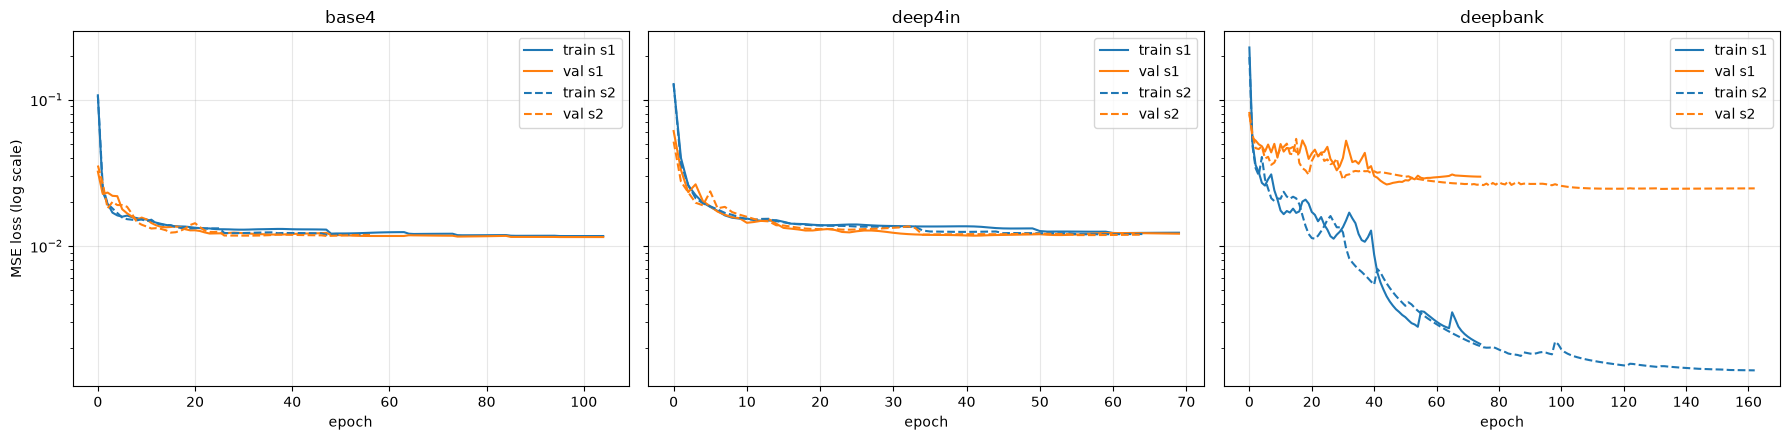

In [3]:
import numpy as np, matplotlib.pyplot as plt

tags = ["base4", "deep4in", "deepbank"]
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5), sharey=True)
for ax, tag in zip(axes, tags):
    for seed, ls in ((1, "-"), (2, "--")):
        r = results.get((tag, seed))
        if r is None:
            continue
        h = r["net"].history.history
        ax.plot(h["loss"], ls, color="tab:blue", label=f"train s{seed}")
        ax.plot(h["val_loss"], ls, color="tab:orange", label=f"val s{seed}")
        print(f"{tag} s{seed}: best val loss {min(h['val_loss']):.5f} at epoch {int(np.argmin(h['val_loss']))+1}")
    ax.set_yscale("log"); ax.set_title(tag); ax.set_xlabel("epoch"); ax.grid(alpha=0.3); ax.legend()
axes[0].set_ylabel("MSE loss (log scale)")
plt.tight_layout()
plt.savefig("deep_trig_run/loss_curves.png", dpi=130)
plt.show()